### Username: aancha.14.2025
### Course: MSc Data Science (EMATM0048); Software Development: Programming and Algorithms (SDPA)

### Name: Aanchala Bhongade; Student no.: 2830709

### Part 2: Data Analysis

# Analysis of Blockchain Security: Market Volatility vs. Crime Severity

## 1. Introduction
In this project, I investigate the relationship between cryptocurrency market conditions and security breaches. Specifically, does the 'hype' of Bull Market lead to more frequent or more severe financial crimes compared to a Bear Market?

## 1.1 Libraries
I am using standard Python Libraries for data collection and the analysis:
1. **'requests'**: To crawl data from external APIs (DefiLlama & Binance).
2. **'pandas'**: For data cleaning and merging.
4. **'matplotlib & seaborn'**: For data visualisation of distribution of financial losses.
5. **'scipy.stats'**: Used for statistical analysis like hypothesis testing (T-Test).

In [2]:
import requests
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import time
from scipy import stats
from datetime import datetime

#setting the visual style
sns.set_theme(style="whitegrid")
print("Libraries are imported successfully....")

Libraries are imported successfully....


## 2. Data Collection

### 2.1 Source A: Crime Data (DefiLlama)
I am extracting the data from the **DefiLlama Hacks API**. It is a open souce dataset that tracks Decentralised Finance (DeFi) protocol breaches.
* **Method:** API Request ('requests.get')
* **Variables:** 'timestamp_s', 'target', 'amount_usd', 'category' and 'blockchain'.

In [7]:
#Getting hacks data from DefiLlama
url_hacksdata = "https://api.llama.fi/hacks"

try:
    print("Requesting the data..")
    response = requests.get(url_hacksdata)
    response.raise_for_status()
    data = response.json()
    
    #creating a dataframe with the help of list of dictionaries
    df_hacks = pd.DataFrame(data)
    
    #Renaming the columns head
    df_hacks = df_hacks.rename(columns={
        'date': 'timestamp_s',
        'name': 'target',
        'amount': 'amount_usd',
        'classification': 'category',
        'chain': 'blockchain'
    })
    
    df_hacks = df_hacks[df_hacks['amount_usd'] > 0].copy()
    
    
    print(f"Sucessfully collected {len(df_hacks)} hacks record.")
    
except Exception as e:
    print(f"Error in fetching the data: {e}")
    
df_hacks.head()

Requesting the data..
Sucessfully collected 429 hacks record.


,timestamp_s,target,category,technique,amount_usd,blockchain,bridgeHack,targetType,source,returnedFunds,defillamaId,language,parentProtocolId
0,1711065600,Super Sushi Samurai,Protocol Logic,Infinite Mint and Dump,4800000.0,[Blast],False,Gaming,https://rekt.news/sss-rekt/,NaN,NaN,Solidity,NaN
1,1709856000,Unizen,Protocol Logic,External Call Vulnerability,2100000.0,[Ethereum],False,DeFi Protocol,https://twitter.com/peckshield/status/17662104...,2100000.0,1336.0,Solidity,NaN
2,1621814400,AutoShark,Ecosystem,Flashloan Incentive Rewards Exploit,745000.0,[BSC],False,DeFi Protocol,https://watchpug.medium.com/sharkfinance-perfo...,NaN,1074.0,None,NaN
3,1630627200,Siren,Smart Contract Language,Reentrancy,3450000.0,[Polygon],False,DeFi Protocol,https://twitter.com/BlockSecTeam/status/143368...,NaN,203.0,Solidity,NaN
4,1704585600,MangoFarmSol,Rugpull,Frontend Attack,2000000.0,[Solana],False,DeFi Protocol,https://cointelegraph.com/news/funds-mangofarm...,NaN,NaN,Rust,NaN


### 2.2 Source B: Market Price Data (Binance)
I am collecting this data for comparing hacks against market price fluctuations, getting the hostorical Ethereum prices.
* **Method:** using *Binance Public API* for data, it allows to get hacks for approx. 1000 days.
* **Variables:** 'timestamp_ms' and 'eth_price'.

In [8]:
#collecting market price data from Binanace Public API

url_market = "https://api.binance.com/api/v3/klines"
params = {'symbol': 'ETHUSDT', 'interval': '1d', 'limit': '1000'}

try:
    print("Requesting the dataset..")
    response = requests.get(url_market, params=params)
    response.raise_for_status()
    data = response.json()
    
    
    
    #fetching and renaming the columns of interest
    df_market = pd.DataFrame(data)
    df_market = df_market.iloc[:, [0, 4]]
    df_market.columns = ['timestamp_ms', 'eth_price']
        
    #ensuring price is a float
    df_market['eth_price'] = df_market['eth_price'].astype(float)
    
        
    print(f"Successfully collected {len(df_market)} days of price data.")
        
            
except Exception as e:
    print(f"error in fetching price data: {e}")
    
df_market.head()

Requesting the dataset..
Successfully collected 1000 days of price data.


,timestamp_ms,eth_price
0,1678406400000,1426.44
1,1678492800000,1471.97
2,1678579200000,1580.33
3,1678665600000,1673.45
4,1678752000000,1699.40


## 3. Data Preparation and Cleaning
Both the datasets uses different time formats, DefiLlama uses seconds, while Binance uses miliseconds.

**Steps involved:**
1. **Data normalisation:** converting both time formats to python 'datetime' and extracting just the 'Date' (YYYY-MM-DD).
2. **Merging:** merging inner join on 'Date' column to link every hack to the ETH price on that exact date.
3. **Selection:** Selected the columns of interest.
4. **Cleaning:** selecting the columns of interest and handling the missing values.

In [15]:
#converting DefiLlama dates (seconds)
df_hacks['date_obj'] = pd.to_datetime(df_hacks['timestamp_s'], unit='s')
df_hacks['date_only'] = df_hacks['date_obj'].dt.date

#converting Binance dates (miliseconds)
df_market['date_obj'] = pd.to_datetime(df_market['timestamp_ms'], unit='ms')
df_market['date_only'] = df_market['date_obj'].dt.date

#merging the datasets
df_final = pd.merge(df_hacks, df_market, on='date_only', how='inner')


#cleaning the dataset
required_columns = ['date_only', 'target', 'amount_usd', 'eth_price', 'blockchain', 'category']
df_clean = df_final[required_columns].copy()
df_clean = df_clean.rename(columns={'date_only': 'date'})


#handling the missing values
df_clean = df_clean.dropna()

df_clean.head()

df_clean.to_csv('blockchain_security_dataset.csv', index=False)
print("File saved successfully")

File saved successfully


## 4. Exploratory Data Analysis (EDA)

### 4.1 Statistical analysis
Computing key statistics for the numerical variables ('amount_usd' and 'eth_price'). Calculates mean, median and Range.

In [16]:
#statistical analysis
print("\n_________ Statistics for Amount Lost (USD) _________")

#calculating the mean (avg)
mean_loss = df_clean['amount_usd'].mean()
print(f"Mean Loss: ${mean_loss:,.2f}")

#calculating the median
median_loss = df_clean['amount_usd'].median()
print(f"Median Loss: ${median_loss:,.2f}")

#calculating range
max_loss = df_clean['amount_usd'].max()
min_loss = df_clean['amount_usd'].min()
range_loss = max_loss - min_loss

print(f"Max Loss: ${max_loss:,.2f}")
print(f"Min Loss: ${min_loss:,.2f}")
print(f"Range: ${range_loss:,.2f}")

print("\n_________ Statistics for Ethereum Price (USD) _________")
print(f"Average ETH price: ${df_clean['eth_price'].mean():,.2f}")
print(f"Highest ETH price: ${df_clean['eth_price'].max():,.2f}")


_________ Statistics for Amount Lost (USD) _________
Mean Loss: $20,294,404.22
Median Loss: $2,400,000.00
Max Loss: $1,400,000,000.00
Min Loss: $10,850.00
Range: $1,399,989,150.00

_________ Statistics for Ethereum Price (USD) _________
Average ETH price: $2,726.67
Highest ETH price: $4,749.30


### 4.2 Correlation Analysis
This is used to answer the main question here *"Does the price of Ethereum (cryptocurrency) relates with the amount stolen?"*

correation coefficent: 
            amount_usd  eth_price
amount_usd    1.000000  -0.014062
eth_price    -0.014062   1.000000


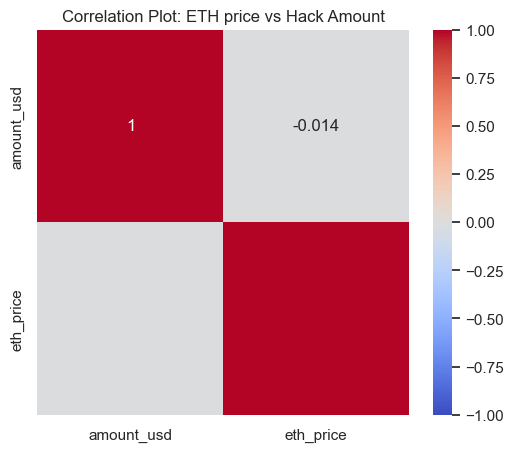

In [17]:
#calculation of correlational coefficient between eth_price and amount_usd
correlation = df_clean[['amount_usd', 'eth_price']].corr()
print("correation coefficent: ")
print(correlation)

#visualisation using heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(correlation, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Plot: ETH price vs Hack Amount')
plt.show()

### Interpretation from the Correlation plot:
**Observation & Inference:** The correation coefficient is low, which shows no strong linear relationship between price of Ethereum and amount lost(severity of a hack). It means higher market prices does not guarantee a huge theft.

### 4.3 Histogram
Visualises the *frequency of different hack sizes.*

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


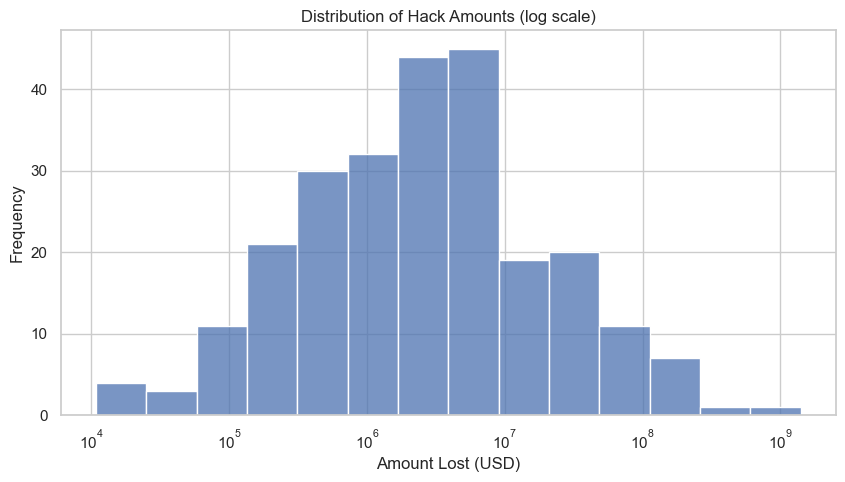

In [19]:
#histogram (Distribution of amount lost); using log scale as amount vary from thousands to billions
plt.figure(figsize=(10, 5))
sns.histplot(df_clean['amount_usd'], log_scale=True)
plt.title('Distribution of Hack Amounts (log scale)')
plt.xlabel('Amount Lost (USD)')
plt.ylabel('Frequency')
plt.show()

### Interpretation from the Histogram:
**Observation & Inference:** We can see data is highly skewed even towards right. It tells that there isn't any single explotation which causes huge loss. It tells that blockchain risks are concentrated but not evenly distributed.

### 4.4 Scatter Plot
This plots **Amount lost** against **ETH price** to check if *higher prices cluster around high hacks.*

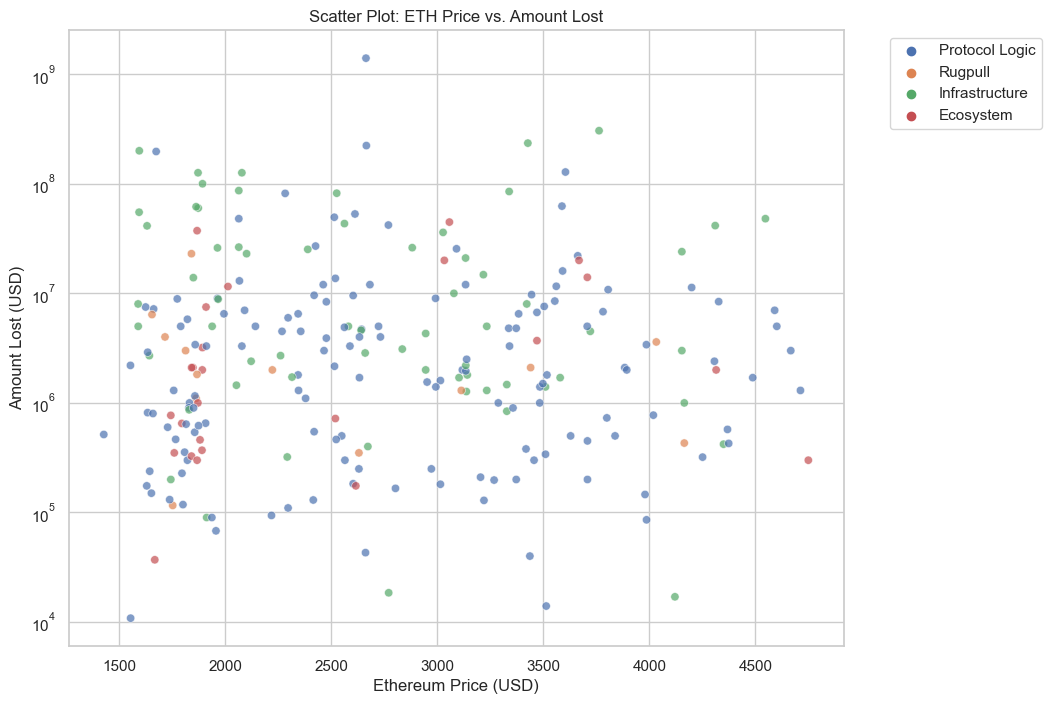

In [20]:
#Scatter plot (ETH price vs Hacks)
plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=df_clean,
    x='eth_price',
    y='amount_usd',
    hue='category',
    alpha=0.7
)
plt.yscale('log')
plt.title('Scatter Plot: ETH Price vs. Amount Lost')
plt.xlabel('Ethereum Price (USD)')
plt.ylabel('Amount Lost (USD)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

### Interpretation from the Scatter Plot:
**Observation & Inference:** The points are scattered across the chart. It is seen high-value hacks occuring at loth low and high ETH prices. It tells that expliotation happens regardless of market conditions.

## 5. Conclusion
### 5.1 Question
Is Blockchain **"Secure"** or a **"Crime Path"**? Are market conditions and platform choices (blockchain) related to severity of financial crimes?

#### Sub-questions:
1. **Correlational Analysis:** Is there any correlation between Ethereum's price and the amount lost?
2. **Hypothesis Testing:** Do high prices *(Bull markets)* result in higher losses than low prices *(Bear markets)*?
3. **Categorical Analysis:** Which Blockchain networks are most frequently tragated and does this choice affect security?

In [43]:
print("_______ 1: Correlational Analysis _______")

#calculating correlation
correlation = df_clean['amount_usd'].corr(df_clean['eth_price'])
print(f"Correlational Coefficient: {correlation:.4f}")

#explanation for the result
if correlation > 0.5:
    print("Strong positive corelation: ETH prices and financial crimes go up together")
elif correlation < -0.5:
    print("Strong negative correlation: ETH prices and financial crime don't go up together")
else:
    print(" Weak or No correlation")

_______ 1: Correlational Analysis _______
Correlational Coefficient: -0.0141
 Weak or No correlation


In [21]:
print("_______ 2: Hypothesis Testing _______")

#finding median prices to split the groups into bear and bull market
median_price = df_clean['eth_price'].median()
print(f"Median price (mid point): ${median_price:.2f}")

#creating groups
bull_market = df_clean[df_clean['eth_price'] > median_price]
bear_market = df_clean[df_clean['eth_price'] <= median_price]

#comparing the averages
bull_avg = bull_market['amount_usd'].mean()
bear_avg = bear_market['amount_usd'].mean()

print(f"Average loss in Bull market: ${bull_avg:,.2f}")
print(f"Average loss in Bear market: ${bear_avg:,.2f}")

#T-Test
t_stat, p_value = stats.ttest_ind(bull_market['amount_usd'], bear_market['amount_usd'], equal_var=False)
print(f"p-value: {p_value:.4f}")

#explanation
if p_value < 0.05:
    print("Conclusion: There is statistical significance difference in severity between Bull and Bear market")
else:
    print("There is no statistical significance difference in severity between Bull and Bear market")

_______ 2: Hypothesis Testing _______
Median price (mid point): $2602.59
Average loss in Bull market: $25,774,119.35
Average loss in Bear market: $14,858,526.80
p-value: 0.3713
There is no statistical significance difference in severity between Bull and Bear market


_______ 3: Categorical Analysis _______
Top 6 Blockchains targated:
blockchain
[Ethereum]    78
[Arbitrum]    25
[BSC]         16
[Base]        12
[Solana]       8
[Optimism]     6
Name: count, dtype: int64


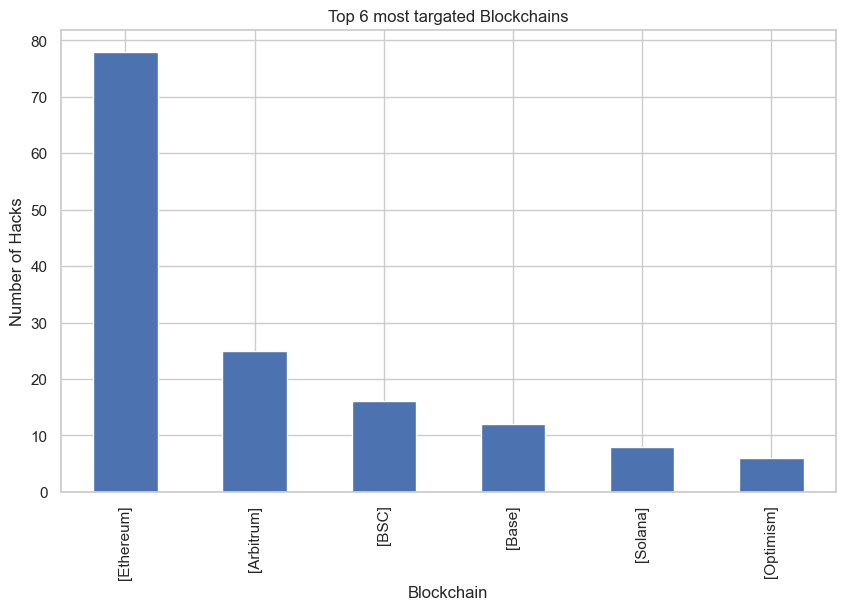

In [22]:
print("_______ 3: Categorical Analysis _______")

#counting how many times each blockchain apperars
chain_count = df_clean['blockchain'].value_counts()

#printing the top 6 of them
print("Top 6 Blockchains targated:")
print(chain_count.head(6))

#using bar graph for visualisation
plt.figure(figsize=(10,6))
chain_count.head(6).plot(kind='bar')
plt.title('Top 6 most targated Blockchains')
plt.ylabel('Number of Hacks')
plt.xlabel('Blockchain')
plt.show()

### 5.2 Summary
The analysis studied about the dual nature of Blockchain: a technology known for security yet is a pathway to many financial crimes. By integrating DefiLlama crime data with Binance market data, I got following conclusions:

1. **The Good (Transparency):** The cash black money is very opaque, but here crypto crime is visible. I successfully tracked and visualised millions of dollars in stolen funds in section 4. 
2. **The Bad (Fragility):** The data tells that while **cryptocurrency** can be secure but the implementation (application layer) is highly fragile. As the crypto crime is visible but the identity and thefts are often irreversible, it just can track the theft has happened.
3. **Market Influence:** Using Hypothesis testing in sub-question2, I studied about does *Bull market* drives security negligence but it resulted in telling it doesn't. Though it is said that, this path is a huge pathway for financial crime but founded no correlation.

#### **Ideas for future work:**
1. Idea 1: 
* Concept: Currently, we treat each hack as an isolated event. But in future, we could use **clustering algorithms** to analyse the *funding wallets* of these attackers. 
* New variables: Introduction of variables like *wallet age*, like how long ago the wallet was created before theft and is the crypto coming from a centralised exchange or a private source.

2. Idea 2:
* Concept: Instead of analysing crimes after they happen, we can do **Predictive Analysis**.
* Scrapping technical variables like code complexity or developer anonmity, is the team public or anonymous?
* Building a ML model: Calculating "risk score" for new projects. Like if a project is highly complex with anonmous team and low audit score so it could flag it as "High probablity for theft" before user invest.

In [24]:
print("__________________ End of Part 2: Data Analysis __________________")

__________________ End of Part 2: Data Analysis __________________
